In [1]:
import sys
sys.path.insert(1, '/home/santolam/MyPythonLibrary/MAR-RECAP/libmar/')
import climbasis as climb
from climbasis import *
import domain as dom
import myplot
import numpy.ma as ma
from myplot import *
import obsinfo as obs
from obsinfo import *



In [2]:
domainM='GRq'; nx=ny=10

In [3]:
## Model MAR
domain='GRc'
sourceDataGrid='/home/santolam/'
fileName_grM='NST.2000.01.01.00.GRc.nc'
dsM= xr.open_dataset(sourceDataGrid+fileName_grM)
LONS=dsM.LON[ny:-ny,nx:-nx].values;LATS=dsM.LAT[ny:-ny,nx:-nx].values
dsSH=dsM.SH[ny:-ny,nx:-nx];dsICE=dsM.ICE[ny:-ny,nx:-nx]

dsSH=dsSH.rename({'y': 'Y','x':'X'})

In [4]:
#ds_TF=ds_SF+ds_RF

In [5]:
####
##Donnes meteo
sourceData='/bettik/PROJECTS/pr-regional-climate/santolam/glacioclim/donnees_precip/'
#
#Precipitation_Khare_corrected_Nov2016_Nov2023_final.xlsx
#Precipitation_Pyramid_Pheriche_corrected_Apr2016_Nov2023_final.xlsx
#Precipitation_Pyramid_Pheriche_corrected_Dec2012_Apr2016_final.xlsx

In [ ]:
#https://github.com/Andeol-ramb/MAR_HMA_GLACIOCLIM_Comparisons/blob/main/Sensitivity_Test_MAR/Sensitivity_Test_Pyramide_Precip.ipynb
####
## Opening Pheriche+Khare
####

sourceDataSta=sourceData#'/Users/santolam/Data/glacioclim/donnees_precip/'
path1 =sourceDataSta+"/Precipitation_Pyramid_Pheriche_corrected_Dec2012_Apr2016_final.xlsx"
xl_data1=pd.ExcelFile(path1)

dfs1= {sheet_name: xl_data1.parse(sheet_name) 
       for sheet_name in xl_data1.sheet_names}

DataPyramid_Pheriche12_16=dfs1['Precip_data_Dec12_Apr16']

NameVarsPP12_16=['TimeY','RRYhourly','RRYcumul','TimeH','RRHhourly','RRHcumul']
UnitVarsPP16_23=['data/hour','mm','mm','data/hour','mm','mm',]

dfile1P12_16= pd.DataFrame(data=DataPyramid_Pheriche12_16.loc[10:])
df1P12_16=pd.DataFrame(dfile1P12_16.values, columns=NameVarsPP12_16)

df1P12_16['TimeY'] = df1P12_16['TimeY'].dt.round('h')

path =sourceDataSta+"/Precipitation_Pyramid_Pheriche_corrected_Apr2016_Nov2023_final.xlsx"
xl_data=pd.ExcelFile(path)

dfs = {sheet_name: xl_data.parse(sheet_name) 
       for sheet_name in xl_data.sheet_names}
DataPyramid_Pheriche16_23=dfs['Precip_data_Apr16_Nov23']

NameVarsPP16_23=['TimeY','TairY','uY','RHY','WMOphaseY','RRYhourly','RRYcumul','TimeH','TairH','uH','RHh','WMOphaseH','RRHhourly','RRHcumul']
UnitVarsPP16_23=['data/hour','(°C)','(ms-1)','(%)','mm','mm','data/hour','(°C)','(ms-1)','(%)','mm','mm',]

dfile1P16_23= pd.DataFrame(data=DataPyramid_Pheriche16_23.loc[10:57630]) #3399 marche, Toujours la même taille jusque 3399 puis toujours lenght var=t-1 par la suite 
#CHANGEMENT DANS TIME:3389 	2016-09-15 17:59:59.!999! / 2016-09-15 18:59:59.!998! 
#donc erreur à chaque changement de décimale, corriger cette data avant tout autre chose


dfile2P16_23=pd.DataFrame(data=DataPyramid_Pheriche16_23.loc[57632:]) 
df1P16_23=pd.DataFrame(dfile1P16_23.values, columns=NameVarsPP16_23)
df2P16_23=pd.DataFrame(dfile2P16_23.values, columns=NameVarsPP16_23)
df1P16_23['TimeY'] = df1P16_23['TimeY'].dt.round('h')
df2P16_23['TimeY'] = df2P16_23['TimeY'].dt.round('30min')

#Definition d'une fréquence permettant par la suite le traitement avec des Xarray
def NewTime(df, NameVar, values, freq):
    time = pd.to_datetime(df['TimeY'].values)
    ds = xr.Dataset({NameVar: ("time", np.asarray(values))}, coords={"time": time})
    return ds
# Time step: 1h

RR1_PY=[float(thing) for thing in df1P12_16['RRYhourly'].values]
RRY1_PY = [float(thing) for thing in df1P16_23['RRYhourly'].values]
dsY1_PY = NewTime(df1P16_23, 'RRYhourly', RRY1_PY, '1h')
dsRR1_PY= NewTime(df1P12_16, 'RRYhourly', RR1_PY, '1h')

# Time step : 30 min 
RRY2_PY = [float(thing) for thing in df2P16_23['RRYhourly'].values]
dsY2_PY = NewTime(df2P16_23, 'RRYhourly', RRY2_PY, '30min')
RR_PY = xr.concat([dsRR1_PY,dsY1_PY, dsY2_PY], dim='time')


RR1_PH=[float(thing) for thing in df1P12_16['RRHhourly'].values]
RRY1_PH = [float(thing) for thing in df1P16_23['RRHhourly'].values]
dsY1_PH = NewTime(df1P16_23, 'RRHhourly', RRY1_PH, '1h')
dsRR1_PH= NewTime(df1P12_16, 'RRHhourly', RR1_PH, '1h')

# Time step : 30 min 
RRY2_PH = [float(thing) for thing in df2P16_23['RRHhourly'].values]
dsY2_PH = NewTime(df2P16_23, 'RRHhourly', RRY2_PH, '30min')
RR_PH = xr.concat([dsRR1_PH,dsY1_PH, dsY2_PH], dim='time')

#####
#
#Khare
#
#####
fileName_KH='Precipitation_Khare_corrected_Nov2016_Nov2023_final.xlsx'
xl_file_KH = pd.ExcelFile(sourceDataSta+fileName_KH)
print(xl_file_KH)
#
dfs_KH = {sheet_name: xl_file_KH.parse(sheet_name) 
          for sheet_name in xl_file_KH.sheet_names}

NameVars_KH=['Time','Tair' ,'u' ,'RH', 'Phase_WMO','RR_WMO_Half-hourly_values','RR_WMO_Khare_cumulated']
UnitVars_KH=['time','(°C)','(ms-1)','(%)','phase','mm w.e.','mm w.e.']

##Define new DataFrame and changing name of columns
dfile_KH = pd.DataFrame(data=dfs_KH["Precip_data_Nov16_Nov23"].loc[8:])
df_KH=pd.DataFrame(dfile_KH.values, columns=NameVars_KH)

path =sourceDataSta+fileName_KH
xl_data=pd.ExcelFile(path)
dfs = {sheet_name: xl_data.parse(sheet_name) 
       for sheet_name in xl_data.sheet_names}
DataKhare16_23=dfs['Precip_data_Nov16_Nov23']
NameVarsPP16_23=['Time','Tair','u','RH','WMOphase','RRhourly','RRcumul']
UnitVarsPP16_23=['data/hour','(°C)','(ms-1)','(%)','mm','mm']
dfileP16_23= pd.DataFrame(data=DataKhare16_23.loc[10:])
dfP16_23=pd.DataFrame(dfileP16_23.values, columns=NameVarsPP16_23)

RR_KH=[float(i) for i in dfP16_23.RRhourly.values] 
def NewTime(df, NameVar, values, freq):
    time = pd.to_datetime(df['Time'].values)
    ds = xr.Dataset({NameVar: ("time", np.asarray(values))}, coords={"time": time})
    return ds
RR_KH=NewTime(dfP16_23,'RRhourly',RR_KH,'30min')
#RR=RR.sel(time=slice('2016'))


rr_hourly_PY=RR_PY.resample(time='1H').sum()
#rr_hourly_PY=RR_PY.RRYhourly

rr_hourly_PH=RR_PH.resample(time='1H').sum()
#rr_hourly_PH=RR_PH.RRHhourly

rr_hourly_KH=RR_KH.resample(time='1H').sum()
#rr_hourly_KH=RR_KH.RRhourly

idatePY = str(rr_hourly_PY.time[0].values)[:10]
fdatePY = str(rr_hourly_PY.time[-1].values)[:10]
idatePH = str(rr_hourly_PH.time[0].values)[:10]
fdatePH = str(rr_hourly_PH.time[-1].values)[:10]
idateKH = str(rr_hourly_KH.time[0].values)[:10]
fdateKH = str(rr_hourly_KH.time[-1].values)[:10]


In [ ]:
rr_hourly_KH.time

In [ ]:
#print(rr_hourly_KH)

In [ ]:
###
## PYRAMID Salerno
### 

In [ ]:
sourceData='/bettik/PROJECTS/pr-regional-climate/santolam/PYRAMID_NETWORK_DATA_v3/'

file_AWS0='AWS0_Z5035_Lvl1.csv'
file_AWS1='AWS1_Z5035_Lvl1.csv'
file_AWS2='AWS2_Z4260_Lvl1.csv'
file_AWS3='AWS3_Z2660_Lvl1.csv'
file_AWS4='AWS4_Z5600_Lvl1.csv'
file_AWS5='AWS5_Z3570_Lvl1.csv'
file_AWSSC='AWSSC_Z7986_Lvl1.csv'
file_CNG='CNG_SNP_Z5700_Lvl1.csv'
file_mon_Pyr='Pyramid_Z5035_lvl2.csv'

# Store filenames in a dictionary for easy looping
files = {
    'AWS0': file_AWS0,
    'AWS1': file_AWS1,
    'AWS2': file_AWS2,
    'AWS3': file_AWS3,
    'AWS4': file_AWS4,
    'AWS5': file_AWS5,
    'AWSSC': file_AWSSC,
    'CNG': file_CNG,
    #'Pyramid': file_mon_Pyr
}
dfs = {}
for name, fname in files.items():
    path = os.path.join(sourceData, fname)
    
    # Read semicolon-delimited CSV
    df = pd.read_csv(path, sep=';')
    
    # Combine into datetime
    df['TIMESTAMP'] = pd.to_datetime(dict(
        year=df['year'],
        month=df['month'],
        day=df['day'],
        hour=df['hour']
    ))
    
    # Set datetime index and drop date columns
    df.set_index('TIMESTAMP', inplace=True)
    df.drop(columns=['year', 'month', 'day', 'hour'], inplace=True)
    
    # Replace physically impossible values (< -100) with NaN
    df[df < -100] = np.nan
    
    # Store
    dfs[name] = df
    
# Optional: unpack for direct access
df_AWS0  = dfs['AWS0']
df_AWS1  = dfs['AWS1']
df_AWS2  = dfs['AWS2']
df_AWS3  = dfs['AWS3']
df_AWS4  = dfs['AWS4']
df_AWS5  = dfs['AWS5']
df_AWSSC = dfs['AWSSC']
df_CNG   = dfs['CNG']
#df_Pyr   = dfs['Pyramid']

# Quick check
print(df_AWS0.head())

# Daily total precipitation (sum of hourly rates)
rr_AWS0_hourly = df_AWS0['RR']#.resample('D').sum()
rr_AWS1_hourly = df_AWS1['RR']#.resample('D').sum()
rr_AWS2_hourly = df_AWS2['RR']#.resample('D').sum()
rr_AWS3_hourly = df_AWS3['RR']#.resample('D').sum()
rr_AWS4_hourly = df_AWS4['RR']#.resample('D').sum()
rr_AWS5_hourly = df_AWS5['RR']#.resample('D').sum()


In [ ]:
rr_AWS0_hourly

In [ ]:
sourceData='/bettik/PROJECTS/pr-regional-climate/santolam/nat_geo_stations_everest/'
#sourceData='/Users/santolam/Desktop/nat_geo_stations_everest/'
##
file_bc='Base_Camp_20230630.csv'
file_c2='Camp2_20230630.csv'
file_phort='Phortse_20230630.csv'
file_bish='Bishop_Rock_20230630.csv'
file_sc='South_Col_20230630.csv'

df_bc = pd.read_csv(os.path.join(sourceData, file_bc), parse_dates=['TIMESTAMP'])
df_c2 = pd.read_csv(os.path.join(sourceData, file_c2), parse_dates=['TIMESTAMP'])
df_phort = pd.read_csv(os.path.join(sourceData, file_phort), parse_dates=['TIMESTAMP'])
df_bish = pd.read_csv(os.path.join(sourceData, file_bish), parse_dates=['TIMESTAMP'])
df_sc = pd.read_csv(os.path.join(sourceData, file_sc), parse_dates=['TIMESTAMP'])

# Optional: set timestamp as index
for df in [df_bc, df_c2, df_phort, df_bish, df_sc]:
    df.set_index('TIMESTAMP', inplace=True)

# Quick check
print(df_bc.head())

rr_bc_hourly = df_bc['PRECIP']#.resample('D').sum()
rr_phort_hourly = df_phort['PRECIP']#.resample('D').sum()


In [ ]:
###Coordinates

In [ ]:
import pandas as pd
from pyproj import Transformer

# Define the transformer (UTM Zone 45N → WGS84)
transformer = Transformer.from_crs("epsg:32645", "epsg:4326", always_xy=True)

# --- Coordinates conversions (you already have some precomputed) ---
# MN (Mera North)
eastingMN, northingMN = 489885, 3065938
lon_MN, lat_MN = transformer.transform(eastingMN, northingMN)
elev_MN = 5360

# CH (Changri)
lon_CH, lat_CH, elev_CH = 86.77948450, 27.98336311, 5360

# ML (Merala)
lon_ML, lat_ML, elev_ML = 86.900, 27.735, 5352.008

# KH (Khare)
lon_KH, lat_KH, elev_KH = 86.8776142768303, 27.74424682282522, 4888

# PH (Pheriche)
lon_PH, lat_PH, elev_PH = 86.81972903284355, 27.895048949594884, 4260

# PY (Pyramid)
lon_PY, lat_PY, elev_PY = 86.81296905961787, 27.957821815535848, 5035

# MS (Mera South)
eastingMS, northingMS = 487553.653, 3064704.231
lon_MS, lat_MS = transformer.transform(eastingMS, northingMS)
elev_MS = 5360  # estimated same as MN, if not otherwise specified

# MC (Mera Central)
eastingMC, northingMC = 488409.424, 3066148.049
lon_MC, lat_MC = transformer.transform(eastingMC, northingMC)
elev_MC = 5770

# --- Define metadata list ---
stations_info_glacioclim = [
    {"ID": "MN", "Name": "Mera Naulek", "Lat": lat_MN, "Lon": lon_MN, "Elev_m": elev_MN, "Timestep": "1h"},
    {"ID": "CH", "Name": "Changri", "Lat": lat_CH, "Lon": lon_CH, "Elev_m": elev_CH, "Timestep": "1h"},
    {"ID": "ML", "Name": "Mera La", "Lat": lat_ML, "Lon": lon_ML, "Elev_m": elev_ML, "Timestep": "1h"},
    {"ID": "KH", "Name": "Khare", "Lat": lat_KH, "Lon": lon_KH, "Elev_m": elev_KH, "Timestep": "1h"},
    {"ID": "PH", "Name": "Pheriche", "Lat": lat_PH, "Lon": lon_PH, "Elev_m": elev_PH, "Timestep": "1h"},
    {"ID": "PY", "Name": "Pyramid", "Lat": lat_PY, "Lon": lon_PY, "Elev_m": elev_PY, "Timestep": "1h"},
    {"ID": "MS", "Name": "Mera Summir", "Lat": lat_MS, "Lon": lon_MS, "Elev_m": elev_MS, "Timestep": "1h"},
    {"ID": "MC", "Name": "Mera Camp 5770", "Lat": lat_MC, "Lon": lon_MC, "Elev_m": elev_MC, "Timestep": "1h"},
]

# --- Create DataFrame ---
df_stations_glacioclim = pd.DataFrame(stations_info_glacioclim)

# Display neatly
print(df_stations_glacioclim.to_string(index=False, justify='center', col_space=12))


In [ ]:
##
# --- AWS and related station metadata ---

# AWSSC (South Col)
lat_AWSSC, lon_AWSSC, elev_AWSSC = 27.98, 86.76, 7986

# CNG_SNP (Changri Nup)
lat_CNG, lon_CNG, elev_CNG = 27.96, 86.93, 5700

# AWS0 (Pyramid)
lat_AWS0, lon_AWS0, elev_AWS0 = 27.96, 86.81, 5035

# AWS1 (Pyramid)
lat_AWS1, lon_AWS1, elev_AWS1 = 27.96, 86.81, 5035

# AWS2 (Pheriche)
lat_AWS2, lon_AWS2, elev_AWS2 = 27.90, 86.82, 4260

# AWS3 (Lukla)
lat_AWS3, lon_AWS3, elev_AWS3 = 27.70, 86.72, 2660

# AWS4 (Kala Patthar)
lat_AWS4, lon_AWS4, elev_AWS4 = 27.99, 86.83, 5600

# AWS5 (Namche)
lat_AWS5, lon_AWS5, elev_AWS5 = 27.80, 86.71, 3570

# Pyramid (monthly level 2)
lat_Pyr, lon_Pyr, elev_Pyr = 27.96, 86.81, 5035

# Define metadata as a list of dicts
stations_info_salerno = [
    {"ID": "AWSSC", "Name": "South Col", "Lat": 27.98, "Lon": 86.76, "Elev_m": 7986, "Timestep": "1h"},
    {"ID": "CNG_SNP", "Name": "Changri Nup", "Lat": 27.96, "Lon": 86.93, "Elev_m": 5700, "Timestep": "1h"},
    {"ID": "AWS0", "Name": "Pyramid", "Lat": 27.96, "Lon": 86.81, "Elev_m": 5035, "Timestep": "1h"},
    {"ID": "AWS1", "Name": "Pyramid", "Lat": 27.96, "Lon": 86.81, "Elev_m": 5035, "Timestep": "1h"},
    {"ID": "AWS2", "Name": "Pheriche", "Lat": 27.90, "Lon": 86.82, "Elev_m": 4260, "Timestep": "1h"},
    {"ID": "AWS3", "Name": "Lukla", "Lat": 27.70, "Lon": 86.72, "Elev_m": 2660, "Timestep": "1h"},
    {"ID": "AWS4", "Name": "Kala Patthar", "Lat": 27.99, "Lon": 86.83, "Elev_m": 5600, "Timestep": "1h"},
    {"ID": "AWS5", "Name": "Namche", "Lat": 27.80, "Lon": 86.71, "Elev_m": 3570, "Timestep": "1h"},
    {"ID": "PYmon", "Name": "Pyramid (monthly)", "Lat": 27.96, "Lon": 86.81, "Elev_m": 5035, "Timestep": "1month"},
]

# Create DataFrame
df_stations_salerno = pd.DataFrame(stations_info_salerno)

# Display
print(df_stations_salerno)

In [ ]:
#Nat geo
#BASE CAMP AWS (27.9952 N, 86.8406 E, 5315 M ASL)
lat_bc,lon_bs,elev_bc=27.9952, 86.8406, 5315
#CAMP II AWS (27.9810 N, 86.9023 E, 6464 M ASL)
lat_c2,lon_c2,elev_c2=27.9810, 86.9023, 6464 
#PHORTSE AWS (27.8456 N, 86.7472 E, 3810 M ASL)
lat_phort,lon_phort,elev_phort=27.8456, 86.7472, 3810 
#BISHOP ROCK AWS (27.9735 N, 86.9308 E, 8810 M ASL)
lat_bish,lon_bish,elev_bish=27.9735, 86.9308, 8810 
#MT. EVEREST SOUTH COL AWS (27.9719 N, 86.9295 E, 7945 M ASL)
lat_sc,lon_sc,elev_sc=27.9719, 86.9295, 7945


# Define metadata for Everest AWS network
stations_info_everest = [
    {"ID": "bc", "Name": "Base Camp AWS", "Lat": 27.9952, "Lon": 86.8406, "Elev_m": 5315},
    {"ID": "c2", "Name": "Camp II AWS", "Lat": 27.9810, "Lon": 86.9023, "Elev_m": 6464},
    {"ID": "phort", "Name": "Phortse AWS", "Lat": 27.8456, "Lon": 86.7472, "Elev_m": 3810},
    {"ID": "bc", "Name": "Bishop Rock AWS", "Lat": 27.9735, "Lon": 86.9308, "Elev_m": 8810},
    {"ID": "sc", "Name": "Mt. Everest South Col AWS", "Lat": 27.9719, "Lon": 86.9295, "Elev_m": 7945},
]

# Create DataFrame
df_everest_stations = pd.DataFrame(stations_info_everest)

# Display
print(df_everest_stations)

In [ ]:
# --- Merge all station metadata into one unified dictionary ---
stations_all = {}

# Add Salerno AWS
for sta in stations_info_salerno:
    stations_all[sta["ID"]] = (sta["Lat"], sta["Lon"], "SalernoAWS")

# Add Glacioclim AWS
for sta in stations_info_glacioclim:
    stations_all[sta["ID"]] = (sta["Lat"], sta["Lon"], "Glacioclim")

# Add NatGeo / Everest AWS
for sta in stations_info_everest:
    stations_all[sta["ID"]] = (sta["Lat"], sta["Lon"], "NatGeo")

# Check summary
print(f"Total stations merged: {len(stations_all)}")
print(stations_all.keys())

In [ ]:
lat,lon=LATS,LONS
# --------------------------
def nearest_ij(lat2d, lon2d, lat, lon):
    """Return nearest (j, i) indices in the model grid."""
    dist = np.hypot(lat2d - lat, lon2d - lon)
    j, i = np.unravel_index(np.nanargmin(dist), dist.shape)
    return j, i

# --------------------------
# Compute indices + collect summary
# --------------------------
nearest_indices = {}
rows = []

for name, (lat_sta, lon_sta, group) in stations_all.items():
    j, i = nearest_ij(lat, lon, lat_sta, lon_sta)
    nearest_indices[name] = (j, i)
    rows.append({
        "ID": name,
        "Group": group,
        "Station_Lat": lat_sta,
        "Station_Lon": lon_sta,
        "Grid_j": j,
        "Grid_i": i,
        "Model_Lat": float(lat[j, i]),
        "Model_Lon": float(lon[j, i]),
        "Model_Elev_m": float(dsSH.values[j, i])
    })

df_station_to_grid = pd.DataFrame(rows).sort_values(["Group", "ID"]).reset_index(drop=True)

print(df_station_to_grid.to_string(index=False))


In [ ]:
# --------------------------
# Salerno
jAWS0, iAWS0   = nearest_indices["AWS0"]
jAWS1, iAWS1   = nearest_indices["AWS1"]
jAWS2, iAWS2   = nearest_indices["AWS2"]
jAWS3, iAWS3   = nearest_indices["AWS3"]
jAWS4, iAWS4   = nearest_indices["AWS4"]
jAWS5, iAWS5   = nearest_indices["AWS5"]
jAWSSC, iAWSSC = nearest_indices["AWSSC"]
jCNG, iCNG     = nearest_indices["CNG_SNP"]
jPYR2, iPYR2   = nearest_indices["PYmon"]

# Glacioclim
jMN, iMN = nearest_indices["MN"]
jCH, iCH = nearest_indices["CH"]
jML, iML = nearest_indices["ML"]
jKH, iKH = nearest_indices["KH"]
jPH, iPH = nearest_indices["PH"]
jPY, iPY = nearest_indices["PY"]
jMS, iMS = nearest_indices["MS"]
jMC, iMC = nearest_indices["MC"]

# NatGeo (Everest)
jbc, ibc     = nearest_indices["bc"]
jc2, ic2     = nearest_indices["c2"]
jphort, iphort = nearest_indices["phort"]
jbish, ibish   = nearest_indices["bc"]
jsc, isc       = nearest_indices["sc"]

# Optional: save lookup table
df_station_to_grid.to_csv("/home/santolam/station_grid_lookup_MARnxny10.csv", index=False)


In [ ]:
df_station_to_grid

In [ ]:
#Precip
#MAR pixel >Stations sharing same MAR line
#(21,59) > Pyramid, AWS0, AWS1
#(20,59)> Pheriche, AWS2
#(17,57)> AWS3, AWS5

In [ ]:
files = [
#"/bettik/amoryc/MARout/GRq/spin2_SEB/ICE.2013.01-12.q11.nc4",
    #"/bettik/amoryc/MARout/GRq/spin2_SEB/ICE.2014.01-12.q12.nc4",
   # "/bettik/amoryc/MARout/GRq/spin2_SEB/ICE.2021.01-12.q19.nc4",
"/bettik/PROJECTS/pr-regional-climate/santolam/MARout/GRq/spin2/work/ICE.2013.01-12.q11.nc4",
"/bettik/PROJECTS/pr-regional-climate/santolam/MARout/GRq/spin2/work/ICE.2014.01-12.q12.nc4",
"/bettik/PROJECTS/pr-regional-climate/santolam/MARout/GRq/spin2/work/ICE.2021.01-12.q19.nc4"
]

# Open and concatenate along time
ds = xr.open_mfdataset(
    files,
    combine="by_coords",   # safest if time coordinates exist
    parallel=True
)

# Select only rainfall and snowfall
ds_TF_hour_raw = ds.RF+ds.SF

print(ds_TF_hour_raw)

In [ ]:
ds_TF_hourly= ds_TF_hour_raw.rename({'TIME': 'time'})
ds_TF_hourly=ds_TF_hourly[:,ny:-ny,nx:-nx]

In [ ]:
##Glacio
ts_TF_PH=ds_TF_hourly[:,jPH,iPH].sel(time=slice(idatePH,fdatePH))#ts_RF_PH+ts_SF_PH
ts_TF_KH=ds_TF_hourly[:,jKH,iKH].sel(time=slice(idateKH,fdateKH))
ts_TF_PY=ds_TF_hourly[:,jPY,iPY].sel(time=slice(idatePY,fdatePY))

In [ ]:
## Salerno
# Daily total precipitation (sum of hourly rates)
# --- Define date ranges for each AWS based on observations ---
idate_AWS0 = str(rr_AWS0_hourly.index[0].date())
fdate_AWS0 = str(rr_AWS0_hourly.index[-1].date())
idate_AWS1 = str(rr_AWS1_hourly.index[0].date())
fdate_AWS1 = str(rr_AWS1_hourly.index[-1].date())
idate_AWS2 = str(rr_AWS2_hourly.index[0].date())
fdate_AWS2 = str(rr_AWS2_hourly.index[-1].date())
idate_AWS3 = str(rr_AWS3_hourly.index[0].date())
fdate_AWS3 = str(rr_AWS3_hourly.index[-1].date())
idate_AWS4 = str(rr_AWS4_hourly.index[0].date())
fdate_AWS4 = str(rr_AWS4_hourly.index[-1].date())
idate_AWS5 = str(rr_AWS5_hourly.index[0].date())
fdate_AWS5 = str(rr_AWS5_hourly.index[-1].date())

# --- Compute RF, SF, TF for each AWS station ---
ts_TF_AWS0 = ds_TF_hourly[:, jAWS0, iAWS0].sel(time=slice(idate_AWS0, fdate_AWS0))

ts_TF_AWS1 = ds_TF_hourly[:, jAWS1, iAWS1].sel(time=slice(idate_AWS1, fdate_AWS1))

ts_TF_AWS2 = ds_TF_hourly[:, jAWS2, iAWS2].sel(time=slice(idate_AWS2, fdate_AWS2))

ts_TF_AWS3 = ds_TF_hourly[:, jAWS3, iAWS3].sel(time=slice(idate_AWS3, fdate_AWS3))

ts_TF_AWS4 = ds_TF_hourly[:, jAWS4, iAWS4].sel(time=slice(idate_AWS4, fdate_AWS4))

ts_TF_AWS5 = ds_TF_hourly[:, jAWS5, iAWS5].sel(time=slice(idate_AWS5, fdate_AWS5))



In [ ]:
##Nat geo
##
idate_bc     = str(rr_bc_hourly.index[0].date())
fdate_bc     = str(rr_bc_hourly.index[-1].date())

idate_phort  = str(rr_phort_hourly.index[0].date())
fdate_phort  = str(rr_phort_hourly.index[-1].date())

ts_TF_bc = ds_TF_hourly[:, jbc, ibc].sel(time=slice(idate_bc, fdate_bc))

ts_TF_phort = ds_TF_hourly[:, jphort, iphort].sel(time=slice(idate_phort, fdate_phort))



In [ ]:

# --- Observed daily precipitation series ---
stations_rr_hourly_glacioclim = {
    "Pheriche": rr_hourly_PH,
    "Khare": rr_hourly_KH,
    "Pyramid": rr_hourly_PY
}

# --- Model total fall (rain + snow) ---
ts_TF_model_glacioclim = {
    "Pheriche": ts_TF_PH,
    "Khare": ts_TF_KH,
    "Pyramid": ts_TF_PY
}

# --- Station elevations (manually defined or from metadata) ---
elev_station_glacioclim = {
    "Pheriche": 4240,  # m
    "Khare": 4900,
    "Pyramid": 5050
}

# --- Model elevations from dsSH field ---
elev_model_glacioclim = {
    "Pheriche": float(dsSH[jPH, iPH]),
    "Khare": float(dsSH[jKH, iKH]),
    "Pyramid": float(dsSH[jPY, iPY])
}



In [ ]:
# --- Observed daily total precipitation ---
stations_rr_daily_salerno = {
    "AWS0": rr_AWS0_hourly,
    "AWS1": rr_AWS1_hourly,
    "AWS2": rr_AWS2_hourly,
    "AWS3": rr_AWS3_hourly,
    "AWS4": rr_AWS4_hourly,
    "AWS5": rr_AWS5_hourly,
}

# --- Model total fall (rain + snow) for each AWS station ---
ts_TF_model_salerno = {
    "AWS0": ts_TF_AWS0,
    "AWS1": ts_TF_AWS1,
    "AWS2": ts_TF_AWS2,
    "AWS3": ts_TF_AWS3,
    "AWS4": ts_TF_AWS4,
    "AWS5": ts_TF_AWS5,
}

# --- Station elevation (m) ---
elev_station_salerno = {
    "AWS0": elev_AWS0,
    "AWS1": elev_AWS1,
    "AWS2": elev_AWS2,
    "AWS3": elev_AWS3,
    "AWS4": elev_AWS4,
    "AWS5": elev_AWS5,
}

# --- Model grid elevation (from your elevation field, e.g. field_SH) ---
elev_model_salerno = {
    "AWS0": float(dsSH[jAWS0, iAWS0]),
    "AWS1": float(dsSH[jAWS1, iAWS1]),
    "AWS2": float(dsSH[jAWS2, iAWS2]),
    "AWS3": float(dsSH[jAWS3, iAWS3]),
    "AWS4": float(dsSH[jAWS4, iAWS4]),
    "AWS5": float(dsSH[jAWS5, iAWS5]),
}



In [ ]:
rr_phort_hourly[rr_phort_hourly < -100] = np.nan

In [ ]:

# --- Observed daily total precipitation ---
stations_rr_daily_natgeo = {
    "Base Camp": rr_bc_hourly,
    "Phortse": rr_phort_hourly,
}

# --- Model total fall (rain + snow) for each station ---
ts_TF_model_natgeo = {
    "Base Camp": ts_TF_bc,
    "Phortse": ts_TF_phort,
}

# --- Station elevation (from your metadata) ---
elev_station_natgeo = {
    "Base Camp": 5315,  # from your stations_info_everest
    "Phortse": 3810,
}

# --- Model grid elevation (from your elevation field) ---
elev_model_natgeo = {
    "Base Camp": float(dsSH[jbc, ibc]),
    "Phortse": float(dsSH[jphort, iphort]),
}



In [ ]:
stations_dates = pd.DataFrame({
    "Station": ["Pheriche","Khare","Pyramid","AWS0","AWS1","AWS2","AWS3","AWS4","AWS5","Base Camp","Phortse"],
    "Initial date": [idatePH,idateKH,idatePY,idate_AWS0,idate_AWS1,idate_AWS2,idate_AWS3,idate_AWS4,idate_AWS5,idate_bc,idate_phort],
    "Final date": [fdatePH,fdateKH,fdatePY,fdate_AWS0,fdate_AWS1,fdate_AWS2,fdate_AWS3,fdate_AWS4,fdate_AWS5,fdate_bc,fdate_phort]
})

print(stations_dates)

In [ ]:
##AWS0 out of event analisys
##

In [ ]:

#.sel(time=slice(idate_event,fdate_event)
# --- Observed daily total precipitation ---
stations_rr_hourly_all = {
    "Pheriche": rr_hourly_PH,
    "Khare": rr_hourly_KH,
    "Pyramid": rr_hourly_PY,
    "AWS0": rr_AWS0_hourly,
    "AWS1": rr_AWS1_hourly,
    "AWS2": rr_AWS2_hourly,
    "AWS3": rr_AWS3_hourly,
    "AWS4": rr_AWS4_hourly,
    "AWS5": rr_AWS5_hourly,

    "Base Camp": rr_bc_hourly,
    "Phortse": rr_phort_hourly,
}

# --- Model total fall (rain + snow) for each station ---
ts_TF_model_all= {
        "Pheriche": ts_TF_PH,
    "Khare": ts_TF_KH,
    "Pyramid": ts_TF_PY,
        "AWS0": ts_TF_AWS0,
    "AWS1": ts_TF_AWS1,
    "AWS2": ts_TF_AWS2,
    "AWS3": ts_TF_AWS3,
    "AWS4": ts_TF_AWS4,
    "AWS5": ts_TF_AWS5,

    "Base Camp": ts_TF_bc,
    "Phortse": ts_TF_phort,
}

# --- Station elevation (from your metadata) ---
elev_station_all = {
        "Pheriche": 4240,  # m
    "Khare": 4900,
    "Pyramid": 5050,
       "AWS0": elev_AWS0,
    "AWS1": elev_AWS1,
    "AWS2": elev_AWS2,
    "AWS3": elev_AWS3,
    "AWS4": elev_AWS4,
    "AWS5": elev_AWS5,

    "Base Camp": 5315,  # from your stations_info_everest
    "Phortse": 3810,
}

# --- Model grid elevation (from your elevation field) ---
elev_model_all = {
        "AWS0": float(dsSH[jAWS0, iAWS0]),
    "AWS1": float(dsSH[jAWS1, iAWS1]),
    "AWS2": float(dsSH[jAWS2, iAWS2]),
    "AWS3": float(dsSH[jAWS3, iAWS3]),
    "AWS4": float(dsSH[jAWS4, iAWS4]),
    "AWS5": float(dsSH[jAWS5, iAWS5]),
    "Pheriche": float(dsSH[jPH, iPH]),
    "Khare": float(dsSH[jKH, iKH]),
    "Pyramid": float(dsSH[jPY, iPY]),
    "Base Camp": float(dsSH[jbc, ibc]),
    "Phortse": float(dsSH[jphort, iphort]),
}



In [ ]:
##for name in station_names:
 #   print( name,stations_rr_daily_all[name])

In [ ]:
station_names = list(stations_rr_hourly_all.keys())
station_names

In [ ]:
#Precip
#MAR pixel >Stations sharing same MAR line
#(21,59) > Pyramid, AWS0, AWS1
#(20,59)> Pheriche, AWS2
#(17,57)> AWS3, AWS5

In [ ]:
station_styles = {
    "Pheriche":   {"color": "green",         "obs_ls": "--"},
    "Khare":      {"color": "red",           "obs_ls": "--"},
    "Pyramid":    {"color": "blue",          "obs_ls": "--"},
    "AWS0":       {"color": "blue",          "obs_ls": "-."},
    "AWS1":       {"color": "blue",          "obs_ls": ":"},
    "AWS2":       {"color": "green",         "obs_ls": "-."},
    "AWS3":       {"color": "orange",        "obs_ls": "--"},
    "AWS4":       {"color": "darkviolet",    "obs_ls": "--"},
    "AWS5":       {"color": "orange",        "obs_ls": "-."},
    "Base Camp":  {"color": "lightseagreen", "obs_ls": "--"},
    "Phortse":    {"color": "brown",         "obs_ls": "--"},
}

station_names = list(stations_rr_hourly_all.keys())


In [ ]:
stations_dates = pd.DataFrame({
    "Station": ["Pheriche","Khare","Pyramid","AWS0","AWS1","AWS2","AWS3","AWS4","AWS5","Base Camp","Phortse"],
    "Initial date": [idatePH,idateKH,idatePY,idate_AWS0,idate_AWS1,idate_AWS2,idate_AWS3,idate_AWS4,idate_AWS5,idate_bc,idate_phort],
    "Final date": [fdatePH,fdateKH,fdatePY,fdate_AWS0,fdate_AWS1,fdate_AWS2,fdate_AWS3,fdate_AWS4,fdate_AWS5,fdate_bc,fdate_phort]
})

print(stations_dates)

In [ ]:
station_elev = {
    "Pheriche": 4371,
    "Khare": 5045,
    "Pyramid": 5035,
    "AWS0": 5035,
    "AWS1": 5035,
    "AWS2": 4371,
    "AWS3": 3213,
    "AWS4": 5481,
    "AWS5": 4122,
    "Base Camp": 5364,
    "Phortse": 3810,
}


In [ ]:
station_names = sorted(
    station_elev.keys(),
    key=lambda x: station_elev[x]
)

print(station_names)

In [ ]:
print(stations_dates)

In [ ]:
# ==========================================================
letter='a'
idate_event = "2013-10-11"
fdate_event = "2013-10-17"

station_styles = {
    "AWS3":       {"color": "darkblue",        "obs_ls": "--"},
   # "Phortse":    {"color": "blue",         "obs_ls": "--"},
    "AWS5":       {"color": "lightblue",        "obs_ls": "-."},
    "Pheriche":   {"color": "green",         "obs_ls": "--"},
    "AWS2":       {"color": "green",         "obs_ls": "-."},
   # "Khare":      {"color": "orange",           "obs_ls": "--"},
    "Pyramid":    {"color": "darkgoldenrod",          "obs_ls": "--"},
    #"AWS0":       {"color": "darkgoldenrod",          "obs_ls": "-."},
    "AWS1":       {"color": "darkgoldenrod",          "obs_ls": ":"},
   # "Base Camp":  {"color": "brown", "obs_ls": "--"},
    "AWS4":       {"color": "brown",    "obs_ls": "--"},
}
station_names = list(station_styles.keys())


In [ ]:
#rr_AWS4_hourly.loc[idate_event:fdate_event].values

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import xarray as xr
import pandas as pd


# ==========================================================
# Figure
# ==========================================================
fig, ax = plt.subplots(figsize=(18, 10))

lw_obs = 3
lw_mod = 3

# ==========================================================
for name in station_names:

    obs = stations_rr_hourly_all[name]
    model = ts_TF_model_all[name]

    color = station_styles[name]["color"]
    obs_ls = station_styles[name]["obs_ls"]

    # ------------------------------------------------------
    # Convert observations to common format
    # ------------------------------------------------------
    if isinstance(obs, xr.Dataset):

        varname = list(obs.data_vars)[0]
        obs_event = obs[varname].sel(
            time=slice(idate_event, fdate_event)
        )
        x_obs = obs_event.time.values
        y_obs = obs_event.values

    elif isinstance(obs, xr.DataArray):
        obs_event = obs.sel(
            time=slice(idate_event, fdate_event)
        )
        x_obs = obs_event.time.values
        y_obs = obs_event.values

    elif isinstance(obs, pd.Series):

        obs_event = obs.loc[idate_event:fdate_event]

        x_obs = obs_event.index
        y_obs = obs_event.values

    else:
        raise TypeError(
            f"Unsupported type for station {name}: {type(obs)}"
        )

    # ------------------------------------------------------
    model_event = model.sel(
        time=slice(idate_event, fdate_event)
    )

    # ------------------------------------------------------
    # Plot observations
    # ------------------------------------------------------
    ax.plot(
        x_obs,
        y_obs,
        color=color,
        lw=lw_obs,
        linestyle=obs_ls,
        alpha=0.9
    )
#
    # ------------------------------------------------------
    # Plot MAR model
    # ------------------------------------------------------
    ax.plot(
        model_event.time,
        model_event.values,
        color=color,
        lw=lw_mod,
        linestyle='-',
        alpha=0.8
    )

# ==========================================================
# Labels
# ==========================================================
ax.set_xlabel("Date", fontsize=18)

ax.set_ylabel(
    "Hourly precipitation [mm]",
    fontsize=18
)

ax.grid(
    True,
    linestyle='--',
    alpha=0.4
)

ax.tick_params(
    axis='both',
    labelsize=18
)

# ==========================================================
legend_elements = []

for name in station_names:

    color = station_styles[name]["color"]
    obs_ls = station_styles[name]["obs_ls"]
    elev = station_elev[name]

    legend_elements.append(
        Line2D(
            [0], [0],
            color=color,
            lw=3,
            linestyle=obs_ls,
            label=f"{name} ({elev} m)"
        )
    )

# ==========================================================
# MAR example
# ==========================================================
legend_elements.append(
    Line2D(
        [0], [0],
        color='black',
        lw=3,
        linestyle='-',
        label='MAR in station'
    )
)

ax.legend(
    handles=legend_elements,
    fontsize=14,
    frameon=True,
    loc='upper right',
    ncol=1
)
# ==========================================================
# Panel label
# ==========================================================
ax.text(
    0.01, 0.98,
    "a)",
    transform=ax.transAxes,
    fontsize=22,
    fontweight='bold',
    va='top',
    ha='left'
)

# ==========================================================
# Save figure
# ==========================================================
plt.tight_layout()

plotname = (
    f"FIG12{letter}_pre_hourly_event_"
    f"{idate_event}-{fdate_event}_all_stations"
)

plotsDir = (
    "/home/santolam/RECAP/figures/paper_on_validation_RECAP/"
)

plt.savefig(
    f"{plotsDir}{plotname}.png",
    bbox_inches="tight",
    dpi=300
)

print(f"Saved: {plotsDir}{plotname}.png")

plt.show()

In [ ]:
letter='d'
# ==========================================================
# Figure
# ==========================================================
fig, ax = plt.subplots(figsize=(18, 10))

lw_obs = 3
lw_mod = 3

# ==========================================================
for name in station_names:

    obs = stations_rr_hourly_all[name]
    model = ts_TF_model_all[name]

    color = station_styles[name]["color"]
    obs_ls = station_styles[name]["obs_ls"]

    # ------------------------------------------------------
    # Convert observations to common format
    # ------------------------------------------------------
    if isinstance(obs, xr.Dataset):

        varname = list(obs.data_vars)[0]

        obs_event = obs[varname].sel(
            time=slice(idate_event, fdate_event)
        )

        x_obs = obs_event.time.values
        y_obs = obs_event.values

    elif isinstance(obs, xr.DataArray):

        obs_event = obs.sel(
            time=slice(idate_event, fdate_event)
        )

        x_obs = obs_event.time.values
        y_obs = obs_event.values

    elif isinstance(obs, pd.Series):

        obs_event = obs.loc[idate_event:fdate_event]

        x_obs = obs_event.index
        y_obs = obs_event.values

    else:
        raise TypeError(
            f"Unsupported type for station {name}: {type(obs)}"
        )

    # ------------------------------------------------------
    # Cumulative observations
    # ------------------------------------------------------
    y_obs_cumsum = np.nancumsum(y_obs)

    # ------------------------------------------------------
    # Model data
    # ------------------------------------------------------
    model_event = model.sel(
        time=slice(idate_event, fdate_event)
    )

    y_mod_cumsum = np.nancumsum(model_event.values)

    # ------------------------------------------------------
    # Plot cumulative observations
    # ------------------------------------------------------
    ax.plot(
        x_obs,
        y_obs_cumsum,
        color=color,
        lw=lw_obs,
        linestyle=obs_ls,
        alpha=0.9
    )

    # ------------------------------------------------------
    # Plot cumulative MAR model
    # ------------------------------------------------------
    ax.plot(
        model_event.time,
        y_mod_cumsum,
        color=color,
        lw=lw_mod,
        linestyle='-',
        alpha=0.8
    )

# ==========================================================
# Labels
# ==========================================================
ax.set_xlabel(
    "Date",
    fontsize=18
)

ax.set_ylabel(
    "Cumulative precipitation [mm]",
    fontsize=18
)

ax.grid(
    True,
    linestyle='--',
    alpha=0.4
)

ax.tick_params(
    axis='both',
    labelsize=18
)

# ==========================================================
# Legend
# ==========================================================
'''
legend_elements = []

for name in station_names:

    color = station_styles[name]["color"]
    obs_ls = station_styles[name]["obs_ls"]
    elev = station_elev[name]

    legend_elements.append(
        Line2D(
            [0], [0],
            color=color,
            lw=3,
            linestyle=obs_ls,
            label=f"{name} ({elev} m)"
        )
    )

# ==========================================================
# MAR example
# ==========================================================
legend_elements.append(
    Line2D(
        [0], [0],
        color='black',
        lw=3,
        linestyle='-',
        label='MAR in station'
    )
)

ax.legend(
    handles=legend_elements,
    fontsize=14,
    frameon=True,
    loc='upper left',
    ncol=1
)
'''
# ==========================================================
# Panel label
# ==========================================================
ax.text(
    0.01, 0.98,
    f"{letter})",
    transform=ax.transAxes,
    fontsize=22,
    fontweight='bold',
    va='top',
    ha='left'
)

# ==========================================================
# Save figure
# ==========================================================
plt.tight_layout()

plotname = (
    f"FIG12{letter}_pre_cumsum_event_"
    f"{idate_event}-{fdate_event}_all_stations"
)

plotsDir = (
    "/home/santolam/RECAP/figures/paper_on_validation_RECAP/"
)

plt.savefig(
    f"{plotsDir}{plotname}.png",
    bbox_inches="tight",
    dpi=300
)

print(f"Saved: {plotsDir}{plotname}.png")

plt.show()

In [61]:
stations_dates

,Station,Initial date,Final date
0,Pheriche,2012-12-06,2023-11-26
1,Khare,2016-11-25,2023-11-17
2,Pyramid,2012-12-06,2023-11-26
3,AWS0,1994-01-01,2005-12-31
4,AWS1,2000-01-01,2023-12-31
5,AWS2,2001-01-01,2023-12-31
6,AWS3,2002-01-01,2023-12-31
7,AWS4,2009-01-01,2023-12-31
8,AWS5,2001-01-01,2023-12-31
9,Base Camp,2019-10-17,2023-06-30


In [62]:
# ==========================================================
letter='b'
idate_event = "2014-10-10"
fdate_event = "2014-10-18"

station_styles = {
    "AWS3":       {"color": "darkblue",        "obs_ls": "--"},
   # "Phortse":    {"color": "blue",         "obs_ls": "--"},
    "AWS5":       {"color": "lightblue",        "obs_ls": "-."},
    "Pheriche":   {"color": "green",         "obs_ls": "--"},
    "AWS2":       {"color": "green",         "obs_ls": "-."},
   # "Khare":      {"color": "orange",           "obs_ls": "--"},
    "Pyramid":    {"color": "darkgoldenrod",          "obs_ls": "--"},
    #"AWS0":       {"color": "darkgoldenrod",          "obs_ls": "-."},
    "AWS1":       {"color": "darkgoldenrod",          "obs_ls": ":"},
   # "Base Camp":  {"color": "brown", "obs_ls": "--"},
    "AWS4":       {"color": "brown",    "obs_ls": "--"},
}
station_names = list(station_styles.keys())


Saved: /home/santolam/RECAP/figures/paper_on_validation_RECAP/FIG12b_pre_hourly_event_2014-10-10-2014-10-18_all_stations.png


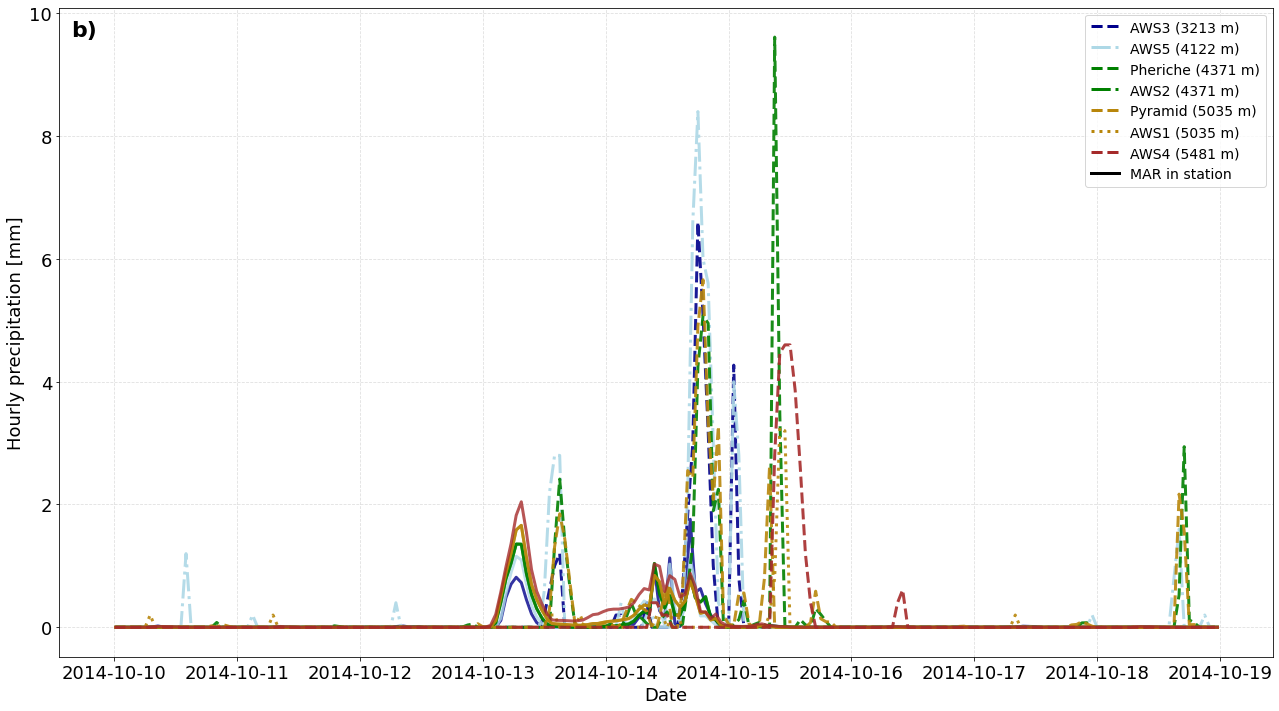

In [64]:

# ==========================================================
# Figure
# ==========================================================
fig, ax = plt.subplots(figsize=(18, 10))

lw_obs = 3
lw_mod = 3

# ==========================================================
for name in station_names:

    obs = stations_rr_hourly_all[name]
    model = ts_TF_model_all[name]

    color = station_styles[name]["color"]
    obs_ls = station_styles[name]["obs_ls"]

    # ------------------------------------------------------
    # Convert observations to common format
    # ------------------------------------------------------
    if isinstance(obs, xr.Dataset):

        varname = list(obs.data_vars)[0]
        obs_event = obs[varname].sel(
            time=slice(idate_event, fdate_event)
        )
        x_obs = obs_event.time.values
        y_obs = obs_event.values

    elif isinstance(obs, xr.DataArray):
        obs_event = obs.sel(
            time=slice(idate_event, fdate_event)
        )
        x_obs = obs_event.time.values
        y_obs = obs_event.values

    elif isinstance(obs, pd.Series):

        obs_event = obs.loc[idate_event:fdate_event]

        x_obs = obs_event.index
        y_obs = obs_event.values

    else:
        raise TypeError(
            f"Unsupported type for station {name}: {type(obs)}"
        )

    # ------------------------------------------------------
    model_event = model.sel(
        time=slice(idate_event, fdate_event)
    )

    # ------------------------------------------------------
    # Plot observations
    # ------------------------------------------------------
    ax.plot(
        x_obs,
        y_obs,
        color=color,
        lw=lw_obs,
        linestyle=obs_ls,
        alpha=0.9
    )
#
    # ------------------------------------------------------
    # Plot MAR model
    # ------------------------------------------------------
    ax.plot(
        model_event.time,
        model_event.values,
        color=color,
        lw=lw_mod,
        linestyle='-',
        alpha=0.8
    )

# ==========================================================
# Labels
# ==========================================================
ax.set_xlabel("Date", fontsize=18)

ax.set_ylabel(
    "Hourly precipitation [mm]",
    fontsize=18
)

ax.grid(
    True,
    linestyle='--',
    alpha=0.4
)

ax.tick_params(
    axis='both',
    labelsize=18
)

# ==========================================================
legend_elements = []

for name in station_names:

    color = station_styles[name]["color"]
    obs_ls = station_styles[name]["obs_ls"]
    elev = station_elev[name]

    legend_elements.append(
        Line2D(
            [0], [0],
            color=color,
            lw=3,
            linestyle=obs_ls,
            label=f"{name} ({elev} m)"
        )
    )

# ==========================================================
# MAR example
# ==========================================================
legend_elements.append(
    Line2D(
        [0], [0],
        color='black',
        lw=3,
        linestyle='-',
        label='MAR in station'
    )
)

ax.legend(
    handles=legend_elements,
    fontsize=14,
    frameon=True,
    loc='upper right',
    ncol=1
)
# ==========================================================
# Panel label
# ==========================================================
ax.text(
    0.01, 0.98,
    f"{letter})",
    transform=ax.transAxes,
    fontsize=22,
    fontweight='bold',
    va='top',
    ha='left'
)

# ==========================================================
# Save figure
# ==========================================================
plt.tight_layout()

plotname = (
    f"FIG12{letter}_pre_hourly_event_"
    f"{idate_event}-{fdate_event}_all_stations"
)

plotsDir = (
    "/home/santolam/RECAP/figures/paper_on_validation_RECAP/"
)

plt.savefig(
    f"{plotsDir}{plotname}.png",
    bbox_inches="tight",
    dpi=300
)

print(f"Saved: {plotsDir}{plotname}.png")

plt.show()

Saved: /home/santolam/RECAP/figures/paper_on_validation_RECAP/FIG12e_pre_cumsum_event_2014-10-10-2014-10-18_all_stations.png


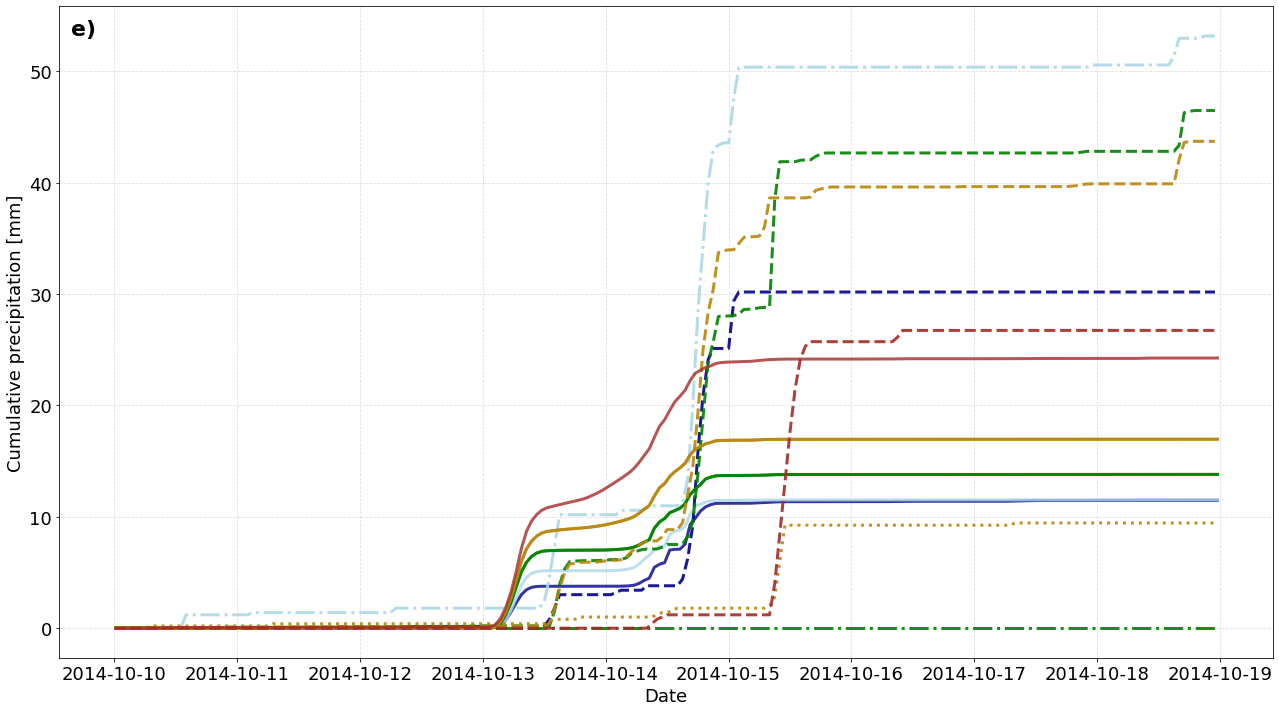

In [65]:
letter='e'
# ==========================================================
# Figure
# ==========================================================
fig, ax = plt.subplots(figsize=(18, 10))

lw_obs = 3
lw_mod = 3

# ==========================================================
for name in station_names:

    obs = stations_rr_hourly_all[name]
    model = ts_TF_model_all[name]

    color = station_styles[name]["color"]
    obs_ls = station_styles[name]["obs_ls"]

    # ------------------------------------------------------
    # Convert observations to common format
    # ------------------------------------------------------
    if isinstance(obs, xr.Dataset):

        varname = list(obs.data_vars)[0]

        obs_event = obs[varname].sel(
            time=slice(idate_event, fdate_event)
        )

        x_obs = obs_event.time.values
        y_obs = obs_event.values

    elif isinstance(obs, xr.DataArray):

        obs_event = obs.sel(
            time=slice(idate_event, fdate_event)
        )

        x_obs = obs_event.time.values
        y_obs = obs_event.values

    elif isinstance(obs, pd.Series):

        obs_event = obs.loc[idate_event:fdate_event]

        x_obs = obs_event.index
        y_obs = obs_event.values

    else:
        raise TypeError(
            f"Unsupported type for station {name}: {type(obs)}"
        )

    # ------------------------------------------------------
    # Cumulative observations
    # ------------------------------------------------------
    y_obs_cumsum = np.nancumsum(y_obs)

    # ------------------------------------------------------
    # Model data
    # ------------------------------------------------------
    model_event = model.sel(
        time=slice(idate_event, fdate_event)
    )

    y_mod_cumsum = np.nancumsum(model_event.values)

    # ------------------------------------------------------
    # Plot cumulative observations
    # ------------------------------------------------------
    ax.plot(
        x_obs,
        y_obs_cumsum,
        color=color,
        lw=lw_obs,
        linestyle=obs_ls,
        alpha=0.9
    )

    # ------------------------------------------------------
    # Plot cumulative MAR model
    # ------------------------------------------------------
    ax.plot(
        model_event.time,
        y_mod_cumsum,
        color=color,
        lw=lw_mod,
        linestyle='-',
        alpha=0.8
    )

# ==========================================================
# Labels
# ==========================================================
ax.set_xlabel(
    "Date",
    fontsize=18
)

ax.set_ylabel(
    "Cumulative precipitation [mm]",
    fontsize=18
)

ax.grid(
    True,
    linestyle='--',
    alpha=0.4
)

ax.tick_params(
    axis='both',
    labelsize=18
)

# ==========================================================
# Legend
# ==========================================================
'''
legend_elements = []

for name in station_names:

    color = station_styles[name]["color"]
    obs_ls = station_styles[name]["obs_ls"]
    elev = station_elev[name]

    legend_elements.append(
        Line2D(
            [0], [0],
            color=color,
            lw=3,
            linestyle=obs_ls,
            label=f"{name} ({elev} m)"
        )
    )

# ==========================================================
# MAR example
# ==========================================================
legend_elements.append(
    Line2D(
        [0], [0],
        color='black',
        lw=3,
        linestyle='-',
        label='MAR in station'
    )
)

ax.legend(
    handles=legend_elements,
    fontsize=14,
    frameon=True,
    loc='upper left',
    ncol=1
)
'''
# ==========================================================
# Panel label
# ==========================================================
ax.text(
    0.01, 0.98,
    f"{letter})",
    transform=ax.transAxes,
    fontsize=22,
    fontweight='bold',
    va='top',
    ha='left'
)

# ==========================================================
# Save figure
# ==========================================================
plt.tight_layout()

plotname = (
    f"FIG12{letter}_pre_cumsum_event_"
    f"{idate_event}-{fdate_event}_all_stations"
)

plotsDir = (
    "/home/santolam/RECAP/figures/paper_on_validation_RECAP/"
)

plt.savefig(
    f"{plotsDir}{plotname}.png",
    bbox_inches="tight",
    dpi=300
)

print(f"Saved: {plotsDir}{plotname}.png")

plt.show()

In [66]:
stations_dates

,Station,Initial date,Final date
0,Pheriche,2012-12-06,2023-11-26
1,Khare,2016-11-25,2023-11-17
2,Pyramid,2012-12-06,2023-11-26
3,AWS0,1994-01-01,2005-12-31
4,AWS1,2000-01-01,2023-12-31
5,AWS2,2001-01-01,2023-12-31
6,AWS3,2002-01-01,2023-12-31
7,AWS4,2009-01-01,2023-12-31
8,AWS5,2001-01-01,2023-12-31
9,Base Camp,2019-10-17,2023-06-30


In [72]:
letter='c'
idate_event = "2021-10-16"
fdate_event = "2021-10-22"

station_styles = {
    "AWS3":       {"color": "darkblue",        "obs_ls": "--"},
    "Phortse":    {"color": "blue",         "obs_ls": "--"},
    "AWS5":       {"color": "lightblue",        "obs_ls": "-."},
    "Pheriche":   {"color": "green",         "obs_ls": "--"},
    "AWS2":       {"color": "green",         "obs_ls": "-."},
    
    "Pyramid":    {"color": "darkgoldenrod",          "obs_ls": "--"},
    #"AWS0":       {"color": "darkgoldenrod",          "obs_ls": "-."},
    "AWS1":       {"color": "darkgoldenrod",          "obs_ls": ":"},
    "Khare":      {"color": "orange",           "obs_ls": "--"},
    "Base Camp":  {"color": "brown", "obs_ls": "-."},
    "AWS4":       {"color": "brown",    "obs_ls": "--"},
}
station_names = list(station_styles.keys())


Saved: /home/santolam/RECAP/figures/paper_on_validation_RECAP/FIG12c_pre_hourly_event_2021-10-16-2021-10-22_all_stations.png


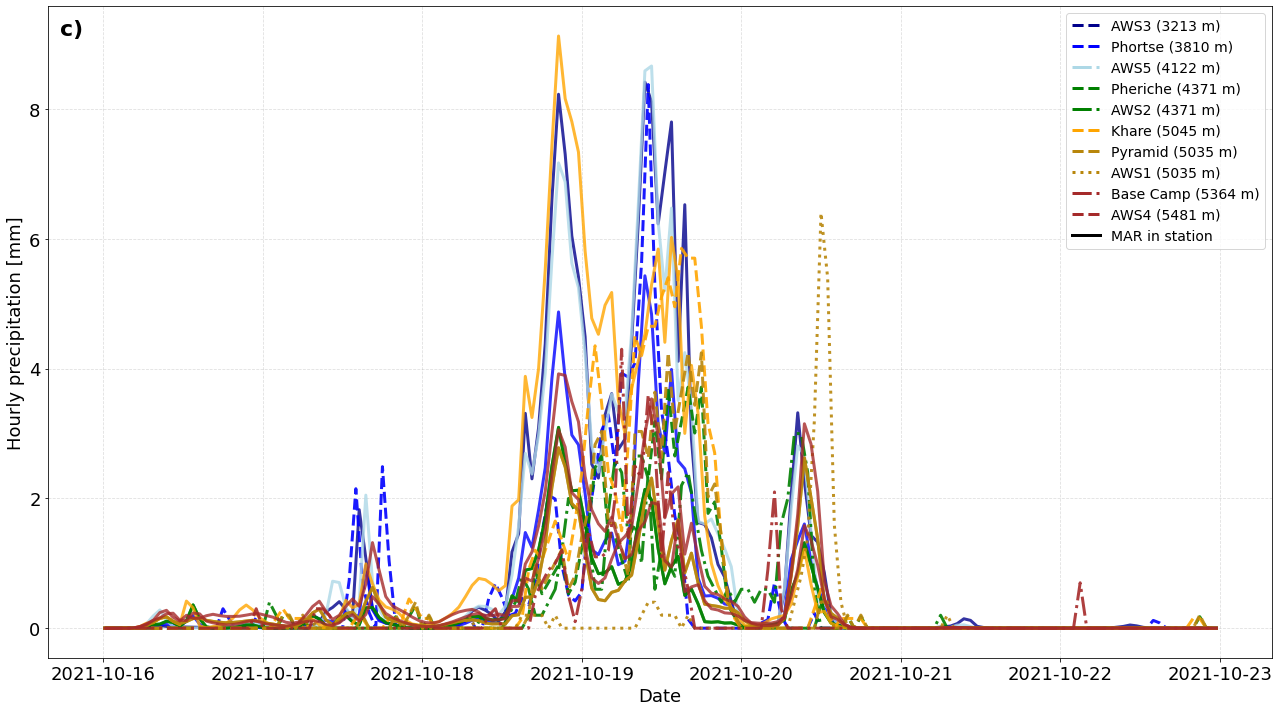

In [70]:

# ==========================================================
# Figure
# ==========================================================
fig, ax = plt.subplots(figsize=(18, 10))

lw_obs = 3
lw_mod = 3

# ==========================================================
for name in station_names:

    obs = stations_rr_hourly_all[name]
    model = ts_TF_model_all[name]

    color = station_styles[name]["color"]
    obs_ls = station_styles[name]["obs_ls"]

    # ------------------------------------------------------
    # Convert observations to common format
    # ------------------------------------------------------
    if isinstance(obs, xr.Dataset):

        varname = list(obs.data_vars)[0]
        obs_event = obs[varname].sel(
            time=slice(idate_event, fdate_event)
        )
        x_obs = obs_event.time.values
        y_obs = obs_event.values

    elif isinstance(obs, xr.DataArray):
        obs_event = obs.sel(
            time=slice(idate_event, fdate_event)
        )
        x_obs = obs_event.time.values
        y_obs = obs_event.values

    elif isinstance(obs, pd.Series):

        obs_event = obs.loc[idate_event:fdate_event]

        x_obs = obs_event.index
        y_obs = obs_event.values

    else:
        raise TypeError(
            f"Unsupported type for station {name}: {type(obs)}"
        )

    # ------------------------------------------------------
    model_event = model.sel(
        time=slice(idate_event, fdate_event)
    )

    # ------------------------------------------------------
    # Plot observations
    # ------------------------------------------------------
    ax.plot(
        x_obs,
        y_obs,
        color=color,
        lw=lw_obs,
        linestyle=obs_ls,
        alpha=0.9
    )
#
    # ------------------------------------------------------
    # Plot MAR model
    # ------------------------------------------------------
    ax.plot(
        model_event.time,
        model_event.values,
        color=color,
        lw=lw_mod,
        linestyle='-',
        alpha=0.8
    )

# ==========================================================
# Labels
# ==========================================================
ax.set_xlabel("Date", fontsize=18)

ax.set_ylabel(
    "Hourly precipitation [mm]",
    fontsize=18
)

ax.grid(
    True,
    linestyle='--',
    alpha=0.4
)

ax.tick_params(
    axis='both',
    labelsize=18
)

# ==========================================================
legend_elements = []

for name in station_names:

    color = station_styles[name]["color"]
    obs_ls = station_styles[name]["obs_ls"]
    elev = station_elev[name]

    legend_elements.append(
        Line2D(
            [0], [0],
            color=color,
            lw=3,
            linestyle=obs_ls,
            label=f"{name} ({elev} m)"
        )
    )

# ==========================================================
# MAR example
# ==========================================================
legend_elements.append(
    Line2D(
        [0], [0],
        color='black',
        lw=3,
        linestyle='-',
        label='MAR in station'
    )
)

ax.legend(
    handles=legend_elements,
    fontsize=14,
    frameon=True,
    loc='upper right',
    ncol=1
)
# ==========================================================
# Panel label
# ==========================================================
ax.text(
    0.01, 0.98,
    f"{letter})",
    transform=ax.transAxes,
    fontsize=22,
    fontweight='bold',
    va='top',
    ha='left'
)

# ==========================================================
# Save figure
# ==========================================================
plt.tight_layout()

plotname = (
    f"FIG12{letter}_pre_hourly_event_"
    f"{idate_event}-{fdate_event}_all_stations"
)

plotsDir = (
    "/home/santolam/RECAP/figures/paper_on_validation_RECAP/"
)

plt.savefig(
    f"{plotsDir}{plotname}.png",
    bbox_inches="tight",
    dpi=300
)

print(f"Saved: {plotsDir}{plotname}.png")

plt.show()

Saved: /home/santolam/RECAP/figures/paper_on_validation_RECAP/FIG12f_pre_cumsum_event_2021-10-16-2021-10-22_all_stations.png


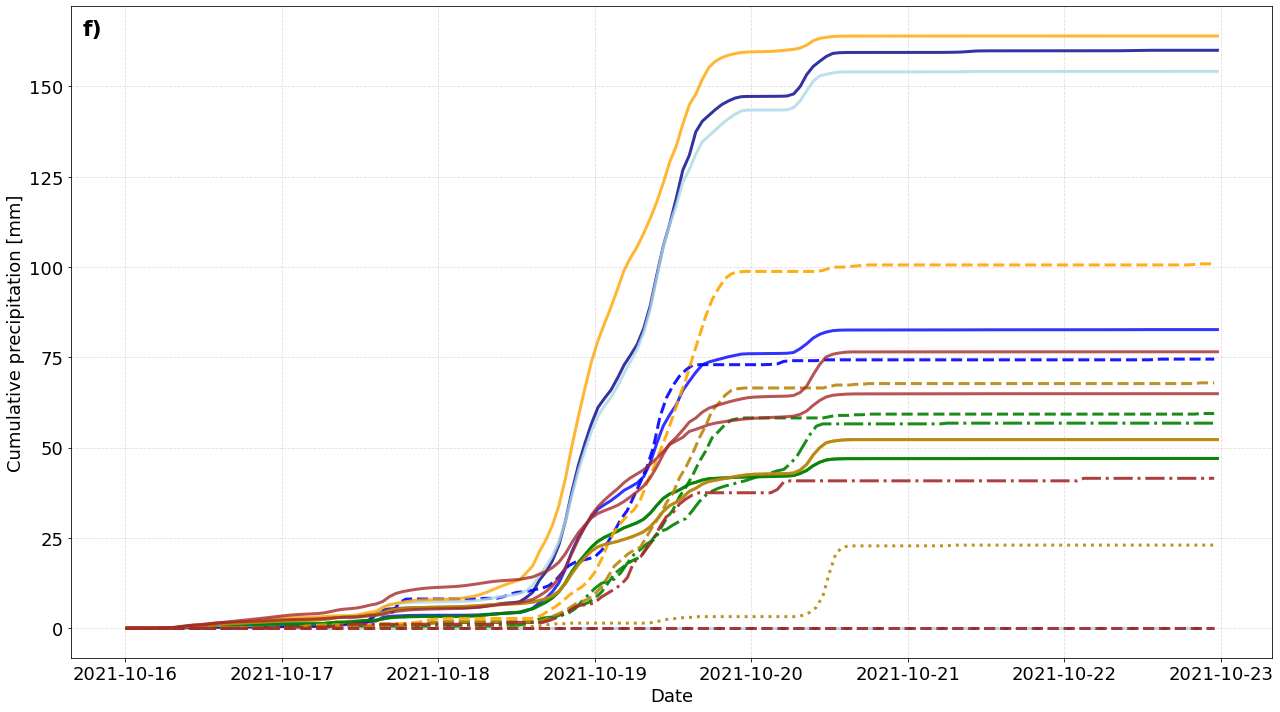

In [71]:
letter='f'
# ==========================================================
# Figure
# ==========================================================
fig, ax = plt.subplots(figsize=(18, 10))

lw_obs = 3
lw_mod = 3

# ==========================================================
for name in station_names:

    obs = stations_rr_hourly_all[name]
    model = ts_TF_model_all[name]

    color = station_styles[name]["color"]
    obs_ls = station_styles[name]["obs_ls"]

    # ------------------------------------------------------
    # Convert observations to common format
    # ------------------------------------------------------
    if isinstance(obs, xr.Dataset):

        varname = list(obs.data_vars)[0]

        obs_event = obs[varname].sel(
            time=slice(idate_event, fdate_event)
        )

        x_obs = obs_event.time.values
        y_obs = obs_event.values

    elif isinstance(obs, xr.DataArray):

        obs_event = obs.sel(
            time=slice(idate_event, fdate_event)
        )

        x_obs = obs_event.time.values
        y_obs = obs_event.values

    elif isinstance(obs, pd.Series):

        obs_event = obs.loc[idate_event:fdate_event]

        x_obs = obs_event.index
        y_obs = obs_event.values

    else:
        raise TypeError(
            f"Unsupported type for station {name}: {type(obs)}"
        )

    # ------------------------------------------------------
    # Cumulative observations
    # ------------------------------------------------------
    y_obs_cumsum = np.nancumsum(y_obs)

    # ------------------------------------------------------
    # Model data
    # ------------------------------------------------------
    model_event = model.sel(
        time=slice(idate_event, fdate_event)
    )

    y_mod_cumsum = np.nancumsum(model_event.values)

    # ------------------------------------------------------
    # Plot cumulative observations
    # ------------------------------------------------------
    ax.plot(
        x_obs,
        y_obs_cumsum,
        color=color,
        lw=lw_obs,
        linestyle=obs_ls,
        alpha=0.9
    )

    # ------------------------------------------------------
    # Plot cumulative MAR model
    # ------------------------------------------------------
    ax.plot(
        model_event.time,
        y_mod_cumsum,
        color=color,
        lw=lw_mod,
        linestyle='-',
        alpha=0.8
    )

# ==========================================================
# Labels
# ==========================================================
ax.set_xlabel(
    "Date",
    fontsize=18
)

ax.set_ylabel(
    "Cumulative precipitation [mm]",
    fontsize=18
)

ax.grid(
    True,
    linestyle='--',
    alpha=0.4
)

ax.tick_params(
    axis='both',
    labelsize=18
)

# ==========================================================
# Legend
# ==========================================================
'''
legend_elements = []

for name in station_names:

    color = station_styles[name]["color"]
    obs_ls = station_styles[name]["obs_ls"]
    elev = station_elev[name]

    legend_elements.append(
        Line2D(
            [0], [0],
            color=color,
            lw=3,
            linestyle=obs_ls,
            label=f"{name} ({elev} m)"
        )
    )

# ==========================================================
# MAR example
# ==========================================================
legend_elements.append(
    Line2D(
        [0], [0],
        color='black',
        lw=3,
        linestyle='-',
        label='MAR in station'
    )
)

ax.legend(
    handles=legend_elements,
    fontsize=14,
    frameon=True,
    loc='upper left',
    ncol=1
)
'''
# ==========================================================
# Panel label
# ==========================================================
ax.text(
    0.01, 0.98,
    f"{letter})",
    transform=ax.transAxes,
    fontsize=22,
    fontweight='bold',
    va='top',
    ha='left'
)

# ==========================================================
# Save figure
# ==========================================================
plt.tight_layout()

plotname = (
    f"FIG12{letter}_pre_cumsum_event_"
    f"{idate_event}-{fdate_event}_all_stations"
)

plotsDir = (
    "/home/santolam/RECAP/figures/paper_on_validation_RECAP/"
)

plt.savefig(
    f"{plotsDir}{plotname}.png",
    bbox_inches="tight",
    dpi=300
)

print(f"Saved: {plotsDir}{plotname}.png")

plt.show()